# Single-Stock Risk Report

A parameterized report for one ticker over one date range, built from the validated
`ohlc_hw_cleaned` table (Part 1). Papermill runs it once per stock in Part 3.

Conventions: returns, volatility, drawdown and Sharpe use **adjusted close**; daily returns are
**log** returns; values stay as fractions and are formatted as percentages only for display.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Database containing ohlc_hw_cleaned (from 01_data_cleaning.ipynb)

In [2]:
import sqlite3
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")

TRADING_DAYS = 252
MIN_PRICES = 21  # 20 returns (one 20-day volatility estimate) need 21 prices
GREEN, RED, GRAY, BLUE = "#2e7d32", "#c62828", "#9e9e9e", "#1565c0"

## 2.2 Load the data

In [3]:
ticker = str(ticker).strip().upper()  # accept " aapl " as AAPL
start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
if start > end:
    raise ValueError(f"start_date {start_date} is after end_date {end_date}")
database = Path(db_path)
if not database.is_file():
    raise FileNotFoundError(f"{database} not found: run 01_data_cleaning.ipynb first")

conn = sqlite3.connect(database.resolve().as_uri() + "?mode=ro", uri=True)  # read-only
known = pd.read_sql_query("SELECT DISTINCT ticker FROM ohlc_hw_cleaned", conn)["ticker"]
if ticker not in set(known):
    conn.close()
    raise ValueError(f"Unknown ticker {ticker!r}; not in ohlc_hw_cleaned")

prices = pd.read_sql_query(
    "SELECT ts, open, high, low, close, adj_close, volume FROM ohlc_hw_cleaned "
    "WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts",
    conn, params=(ticker, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")), parse_dates=["ts"],
).set_index("ts")
conn.close()

if len(prices) < MIN_PRICES:
    raise ValueError(f"{ticker} has only {len(prices)} prices between {start_date} and {end_date}; "
                     f"at least {MIN_PRICES} are needed for 20 returns")

first_date, last_date = prices.index[0].date(), prices.index[-1].date()
print(f"{ticker} from {start_date} to {end_date}: {len(prices)} trading days")
print(f"Actual coverage: {first_date} to {last_date}")
if last_date < (end - pd.offsets.BDay(5)).date():
    print(f"Note: the data for {ticker} ends before the requested end date; "
          "metrics describe the observed period only.")
display(prices.head())
display(prices.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual coverage: 2024-01-02 to 2024-10-18
Note: the data for AAPL ends before the requested end date; metrics describe the observed period only.


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-01-02,187.15,188.44,183.89,185.64,184.94,82488674
2024-01-03,184.22,185.88,183.43,184.25,183.55,58414460
2024-01-04,182.15,183.09,180.88,181.91,181.22,71983570
2024-01-05,181.99,182.76,180.17,181.18,180.50,62379661
2024-01-08,182.09,185.60,181.50,185.56,184.86,59144470


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


## 2.3 Risk metrics

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns, log(p_t / p_{t-1}).

    The first value is NaN (no previous price), not a zero-return day.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: rolling sample std of returns x sqrt(252).

    The first `window` values are NaN (warm-up); they are never filled.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak, (price - cum_max) / cum_max.

    Drawdown can recover; the maximum drawdown for the summary is `drawdown.min()`.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio, (mean * 252 - rf) / (std * sqrt(252)).

    Returns NaN with fewer than two returns or zero volatility (the ratio is undefined).
    """
    r = returns.dropna()
    if len(r) < 2:
        return np.nan
    annual_vol = r.std() * np.sqrt(TRADING_DAYS)
    if not np.isfinite(annual_vol) or np.isclose(annual_vol, 0):
        return np.nan
    return (r.mean() * TRADING_DAYS - risk_free_rate) / annual_vol

In [5]:
# Check the functions by hand on tiny inputs before trusting them on real data.
toy = pd.Series([80.0, 100.0, 70.0, 85.0])
toy_dd = calculate_max_drawdown(toy)
assert np.isclose(toy_dd.min(), -0.30) and np.isclose(toy_dd.iloc[-1], -0.15)  # worst vs final drawdown
toy_r = calculate_returns(toy)
assert np.isnan(toy_r.iloc[0]) and np.isclose(toy_r.iloc[1], np.log(100 / 80))
toy_vol = calculate_volatility(calculate_returns(pd.Series(np.linspace(100, 125, 25))))
assert toy_vol.iloc[:20].isna().all() and toy_vol.iloc[20:].notna().all()  # first estimate needs 21 prices
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.001] * 30)))  # zero volatility -> undefined
print("Hand checks passed.")

Hand checks passed.


In [6]:
adj_close = prices["adj_close"]
returns = calculate_returns(adj_close)
volatility = calculate_volatility(returns)
drawdown = calculate_max_drawdown(adj_close)
sharpe = calculate_sharpe_ratio(returns)
ma_50 = adj_close.rolling(50).mean()  # unavailable until 50 prices exist
mean_vol = volatility.mean()  # mean rolling volatility: threshold for the charts

metrics = pd.DataFrame({"adj_close": adj_close, "log_return": returns, "rolling_vol_20d": volatility,
                        "drawdown": drawdown, "ma_50": ma_50})
display(metrics.iloc[18:23])  # around the end of the volatility warm-up
print(f"Sharpe ratio: {sharpe:.2f}" if np.isfinite(sharpe) else "Sharpe ratio: N/A")
print(f"Maximum drawdown: {drawdown.min():.2%} on {drawdown.idxmin().date()}")
print(f"Mean 20-day rolling volatility: {mean_vol:.2%}")

,adj_close,log_return,rolling_vol_20d,drawdown,ma_50
ts,,,,,
2024-01-29,191.01,-0.003554,NaN,-0.017640,NaN
2024-01-30,187.33,-0.019454,NaN,-0.036567,NaN
2024-01-31,183.70,-0.019568,0.211168,-0.055236,NaN
2024-02-01,186.15,0.013249,0.214625,-0.042635,NaN
2024-02-02,185.15,-0.005386,0.210024,-0.047778,NaN


Sharpe ratio: 1.19
Maximum drawdown: -15.35% on 2024-04-19
Mean 20-day rolling volatility: 23.36%


## 2.4 Visualization

The price line is coloured by the 20-day volatility on each day: red above the report's mean rolling
volatility, green at or below it, grey while the estimate is still warming up. Because the threshold
uses the whole period, the colouring is retrospective.

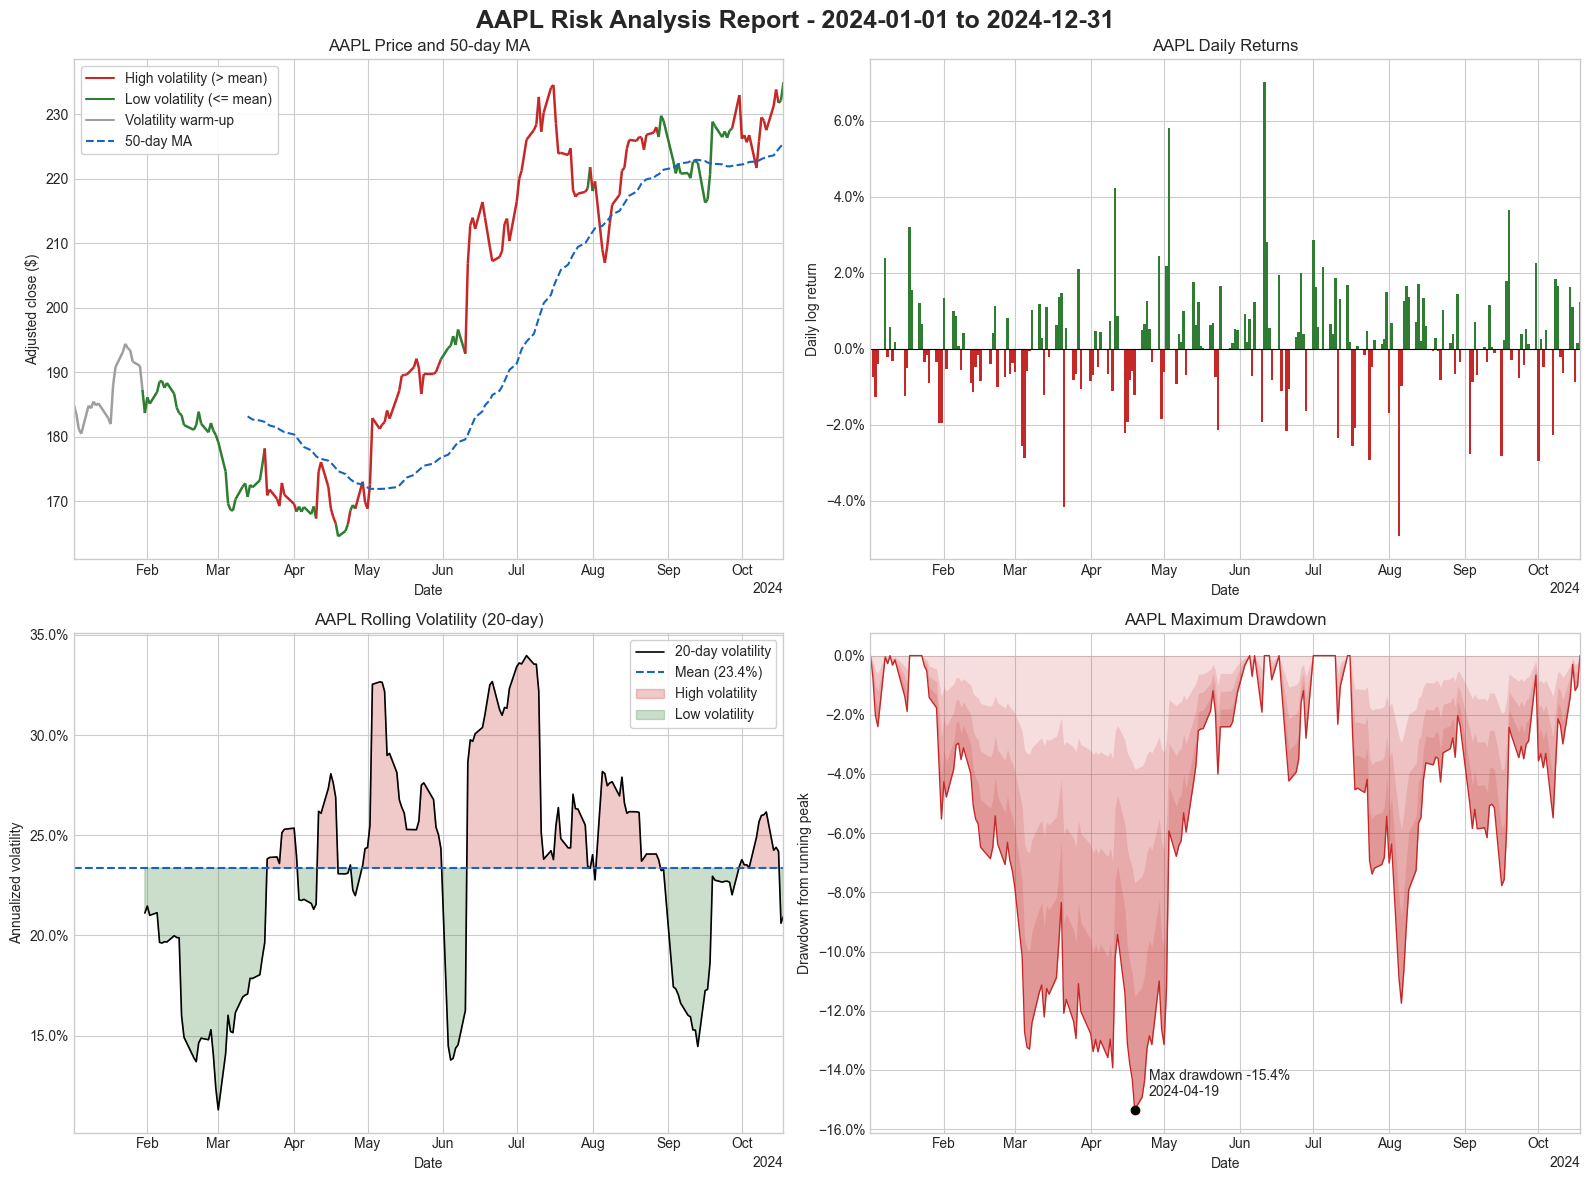

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
(ax_price, ax_ret), (ax_vol, ax_dd) = axes

# Top left: price coloured by volatility regime, plus the 50-day moving average.
x = mdates.date2num(adj_close.index)
points = np.column_stack([x, adj_close.to_numpy()])
segment_vol = volatility.to_numpy()[1:]  # each segment takes the volatility at its end date
colors = np.where(np.isnan(segment_vol), GRAY, np.where(segment_vol > mean_vol, RED, GREEN))
ax_price.add_collection(LineCollection(np.stack([points[:-1], points[1:]], axis=1), colors=colors, linewidths=1.8))
ax_price.autoscale_view()
ax_price.plot(adj_close.index, adj_close, alpha=0)  # invisible copy: lets loc="best" avoid the coloured line
handles = [Line2D([], [], color=RED, label="High volatility (> mean)"),
           Line2D([], [], color=GREEN, label="Low volatility (<= mean)"),
           Line2D([], [], color=GRAY, label="Volatility warm-up")]
if ma_50.notna().any():
    ax_price.plot(ma_50.index, ma_50, color=BLUE, linestyle="--", linewidth=1.5)
    handles.append(Line2D([], [], color=BLUE, linestyle="--", label="50-day MA"))
else:
    ax_price.text(0.02, 0.95, f"50-day MA unavailable: only {len(adj_close)} prices",
                  transform=ax_price.transAxes, va="top", color=GRAY)
ax_price.legend(handles=handles, loc="best", frameon=True, framealpha=0.9)
ax_price.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close ($)")

# Top right: daily returns, green positive / red negative.
r = returns.dropna()
ax_ret.bar(r.index, r, width=1.0, color=np.where(r > 0, GREEN, np.where(r < 0, RED, GRAY)))
ax_ret.axhline(0, color="black", linewidth=0.8)
ax_ret.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_ret.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return")

# Bottom left: rolling volatility with mean line and shaded regimes.
ax_vol.plot(volatility.index, volatility, color="black", linewidth=1.2, label="20-day volatility")
ax_vol.axhline(mean_vol, color=BLUE, linestyle="--", label=f"Mean ({mean_vol:.1%})")
ax_vol.fill_between(volatility.index, volatility, mean_vol, where=volatility > mean_vol,
                    color=RED, alpha=0.25, interpolate=True, label="High volatility")
ax_vol.fill_between(volatility.index, volatility, mean_vol, where=volatility <= mean_vol,
                    color=GREEN, alpha=0.25, interpolate=True, label="Low volatility")
ax_vol.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_vol.legend(loc="best", frameon=True, framealpha=0.9)
ax_vol.set(title=f"{ticker} Rolling Volatility (20-day)", xlabel="Date", ylabel="Annualized volatility")

# Bottom right: drawdown area with a layered red gradient and the maximum marked.
for fraction in (0.0, 0.25, 0.5, 0.75):  # deeper drawdowns get more overlapping layers -> darker
    ax_dd.fill_between(drawdown.index, drawdown, drawdown * fraction, color=RED, alpha=0.15, linewidth=0)
ax_dd.plot(drawdown.index, drawdown, color=RED, linewidth=1)
worst_date, worst = drawdown.idxmin(), drawdown.min()
ax_dd.scatter([worst_date], [worst], color="black", zorder=3)
near_end = worst_date > adj_close.index[0] + (adj_close.index[-1] - adj_close.index[0]) * 0.7
ax_dd.annotate(f"Max drawdown {worst:.1%}\n{worst_date.date()}", (worst_date, worst),  # label left if near the end
               xytext=(-10, 10) if near_end else (10, 10), textcoords="offset points",
               ha="right" if near_end else "left")
ax_dd.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_dd.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from running peak")

for ax in axes.flat:
    ax.grid(True)
    ax.set_xlim(adj_close.index[0], adj_close.index[-1])  # same dates on every panel
    locator = mdates.AutoDateLocator()  # tick spacing and labels adapt to the window length
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
fig.tight_layout()
plt.show()

## 2.5 Summary statistics

Daily statistics use log returns; "Positive Days" divides by **all** nonmissing returns (zero days included).
Whole-period annualized volatility is distinct from the mean rolling volatility used in Part 3.

In [8]:
def summary_statistics(adj_close: pd.Series, returns: pd.Series, drawdown: pd.Series) -> dict:
    """Compute the ten report metrics as fractions (NaN where undefined)."""
    r = returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        "Total Return": adj_close.iloc[-1] / adj_close.iloc[0] - 1,
        "Annualized Return": np.exp(r.sum() * TRADING_DAYS / n) - 1,
        "Annualized Volatility": r.std() * np.sqrt(TRADING_DAYS),
        "Sharpe Ratio": calculate_sharpe_ratio(returns),
        "Maximum Drawdown": drawdown.min(),
        "Best Day": r.max(),
        "Worst Day": r.min(),
        "Positive Days": len(up) / n,
        "Average Up Day": up.mean() if len(up) else np.nan,
        "Average Down Day": down.mean() if len(down) else np.nan,
    }


def format_metric(name: str, value: float) -> str:
    """Display format: signed percent for returns, plain percent for rates, 2 decimals for Sharpe."""
    if not np.isfinite(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name == "Positive Days":
        return f"{value:.1%}"
    if name == "Annualized Volatility":
        return f"{value:.2%}"
    return f"{value:+.2%}"


stats = summary_statistics(adj_close, returns, drawdown)
summary = pd.DataFrame({"Metric": stats.keys(), "Value": [format_metric(k, v) for k, v in stats.items()]})
print(f"{ticker}: {first_date} to {last_date} ({len(prices)} trading days)")
print(summary.to_string(index=False))
n_returns = returns.notna().sum()
if n_returns < TRADING_DAYS:
    print(f"\nNote: annualized figures extrapolate {n_returns} daily returns to a {TRADING_DAYS}-day year; "
          "over a short window they can look much larger than the total return.")

AAPL: 2024-01-02 to 2024-10-18 (202 trading days)
               Metric   Value
         Total Return +27.07%
    Annualized Return +35.03%
Annualized Volatility  23.61%
         Sharpe Ratio    1.19
     Maximum Drawdown -15.35%
             Best Day  +7.01%
            Worst Day  -4.94%
        Positive Days   55.7%
       Average Up Day  +1.08%
     Average Down Day  -1.09%

Note: annualized figures extrapolate 201 daily returns to a 252-day year; over a short window they can look much larger than the total return.


### Outputs collected by the batch runner (Part 3)

Named values are recorded with Scrapbook so `03_run_all_stocks.py` can read them from each successful
report. Undefined values are stored as `None`.

In [9]:
def clean_value(value: float):
    """Convert to a JSON-safe float, or None when undefined."""
    return float(value) if np.isfinite(value) else None


sb.glue("ticker", ticker)
sb.glue("first_date", str(first_date))
sb.glue("last_date", str(last_date))
sb.glue("trading_days", len(prices))
sb.glue("avg_daily_return", clean_value(returns.mean()))  # mean daily log return (fraction)
sb.glue("avg_volatility", clean_value(mean_vol))          # mean of 20-day rolling volatility
sb.glue("max_drawdown", clean_value(drawdown.min()))
sb.glue("sharpe_ratio", clean_value(sharpe))
sb.glue("total_return", clean_value(stats["Total Return"]))